<a href="https://colab.research.google.com/github/ethereal-arko/C_Learning_Journey/blob/main/Calories_burnt_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Calories Burnt Prediction

## Project Overview

This project uses machine learning to predict the number of calories burned during physical exercise based on personal and exercise-related features.

## Objectives

- Explore and understand the dataset.
- Perform exploratory data analysis (EDA).
- Prepare features for machine learning.
- Train an XGBoost regression model.
- Evaluate prediction performance using regression metrics.

## Machine Learning Approach

- **Learning Type:** Supervised Learning
- **Problem Type:** Regression
- **Model:** XGBoost Regressor
- **Evaluation Metrics:** MAE, RMSE, and R² Score


In [2]:
# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset splitting
from sklearn.model_selection import train_test_split

# Regression evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Machine learning model
from xgboost import XGBRegressor

# Display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# Load the datasets
calories = pd.read_csv("/content/calories.csv")
exercise = pd.read_csv("/content/exercise.csv")

print("Calories dataset shape:", calories.shape)
print("Exercise dataset shape:", exercise.shape)

print("\nCalories dataset preview:")
display(calories.head())

print("\nExercise dataset preview:")
display(exercise.head())

Calories dataset shape: (15000, 2)
Exercise dataset shape: (15000, 8)

Calories dataset preview:


,User_ID,Calories
0,14733363,231.0
1,14861698,66.0
2,11179863,26.0
3,16180408,71.0
4,17771927,35.0



Exercise dataset preview:


,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8


## 2. Data Inspection

Before combining the datasets, we inspect their structure, column names, data types, and data quality.

This step helps identify missing values, duplicate records, and potential issues that could affect model training.

In [5]:
# Inspect dataset columns and data types
print("CALORIES DATASET")
print("-" * 50)
print(calories.info())
print("\nColumn names:", calories.columns.tolist())

print("\nEXERCISE DATASET")
print("-" * 50)
print(exercise.info())
print("\nColumn names:", exercise.columns.tolist())

# Check missing values
print("\nMissing values in calories dataset:")
print(calories.isnull().sum())

print("\nMissing values in exercise dataset:")
print(exercise.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows in calories dataset:", calories.duplicated().sum())
print("Duplicate rows in exercise dataset:", exercise.duplicated().sum())

# Statistical summaries
print("\nCalories dataset summary:")
display(calories.describe())

print("\nExercise dataset summary:")
display(exercise.describe())

CALORIES DATASET
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   User_ID   15000 non-null  int64  
 1   Calories  15000 non-null  float64
dtypes: float64(1), int64(1)
memory usage: 234.5 KB
None

Column names: ['User_ID', 'Calories']

EXERCISE DATASET
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   User_ID     15000 non-null  int64  
 1   Gender      15000 non-null  object 
 2   Age         15000 non-null  int64  
 3   Height      15000 non-null  float64
 4   Weight      15000 non-null  float64
 5   Duration    15000 non-null  float64
 6   Heart_Rate  15000 non-null  float64
 7   Body_Temp   15000 non

,User_ID,Calories
count,1.500000e+04,15000.000000
mean,1.497736e+07,89.539533
std,2.872851e+06,62.456978
min,1.000116e+07,1.000000
25%,1.247419e+07,35.000000
50%,1.499728e+07,79.000000
75%,1.744928e+07,138.000000
max,1.999965e+07,314.000000



Exercise dataset summary:


,User_ID,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
count,1.500000e+04,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,1.497736e+07,42.789800,174.465133,74.966867,15.530600,95.518533,40.025453
std,2.872851e+06,16.980264,14.258114,15.035657,8.319203,9.583328,0.779230
min,1.000116e+07,20.000000,123.000000,36.000000,1.000000,67.000000,37.100000
25%,1.247419e+07,28.000000,164.000000,63.000000,8.000000,88.000000,39.600000
50%,1.499728e+07,39.000000,175.000000,74.000000,16.000000,96.000000,40.200000
75%,1.744928e+07,56.000000,185.000000,87.000000,23.000000,103.000000,40.600000
max,1.999965e+07,79.000000,222.000000,132.000000,30.000000,128.000000,41.500000


## 3. Dataset Integration

The exercise and calories datasets contain a common identifier, `User_ID`.

We merge the datasets using this key rather than relying on row positions. Before merging, we verify identifier uniqueness and consistency to ensure that each exercise record is matched with the correct calorie value.

In [6]:
# Check whether User_ID uniquely identifies each record
print("Unique IDs in calories:", calories["User_ID"].nunique())
print("Unique IDs in exercise:", exercise["User_ID"].nunique())

# Validate the merge keys
assert calories["User_ID"].is_unique, "Duplicate User_IDs in calories dataset."
assert exercise["User_ID"].is_unique, "Duplicate User_IDs in exercise dataset."

calories_ids = set(calories["User_ID"])
exercise_ids = set(exercise["User_ID"])

assert calories_ids == exercise_ids, (
    "The datasets contain different User_ID values."
)

# Merge using User_ID
calories_data = pd.merge(
    exercise,
    calories,
    on="User_ID",
    how="inner",
    validate="one_to_one"
)

# Verify the merged dataset
assert len(calories_data) == len(exercise), "Unexpected row loss after merging."

print("\nMerged dataset shape:", calories_data.shape)
print("\nColumns:", calories_data.columns.tolist())

display(calories_data.head())

Unique IDs in calories: 15000
Unique IDs in exercise: 15000

Merged dataset shape: (15000, 9)

Columns: ['User_ID', 'Gender', 'Age', 'Height', 'Weight', 'Duration', 'Heart_Rate', 'Body_Temp', 'Calories']


,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8,231.0
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3,66.0
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7,26.0
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5,71.0
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8,35.0


## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the distribution of features, identify unusual observations, and investigate relationships between exercise measurements and calorie expenditure.

We examine categorical and numerical features separately before studying their relationships with the target variable, `Calories`.

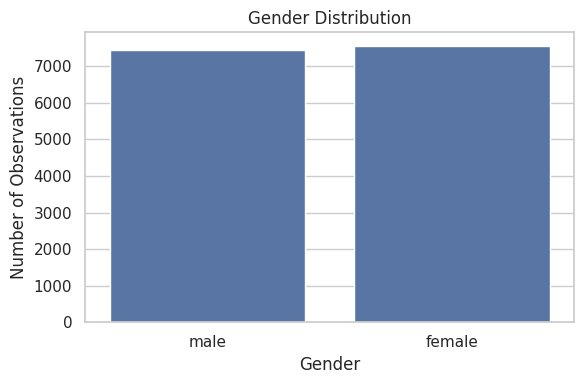


Gender counts:
Gender
female    7553
male      7447
Name: count, dtype: int64


In [7]:
plt.figure(figsize=(6, 4))

sns.countplot(data=calories_data, x="Gender")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

print("\nGender counts:")
print(calories_data["Gender"].value_counts())

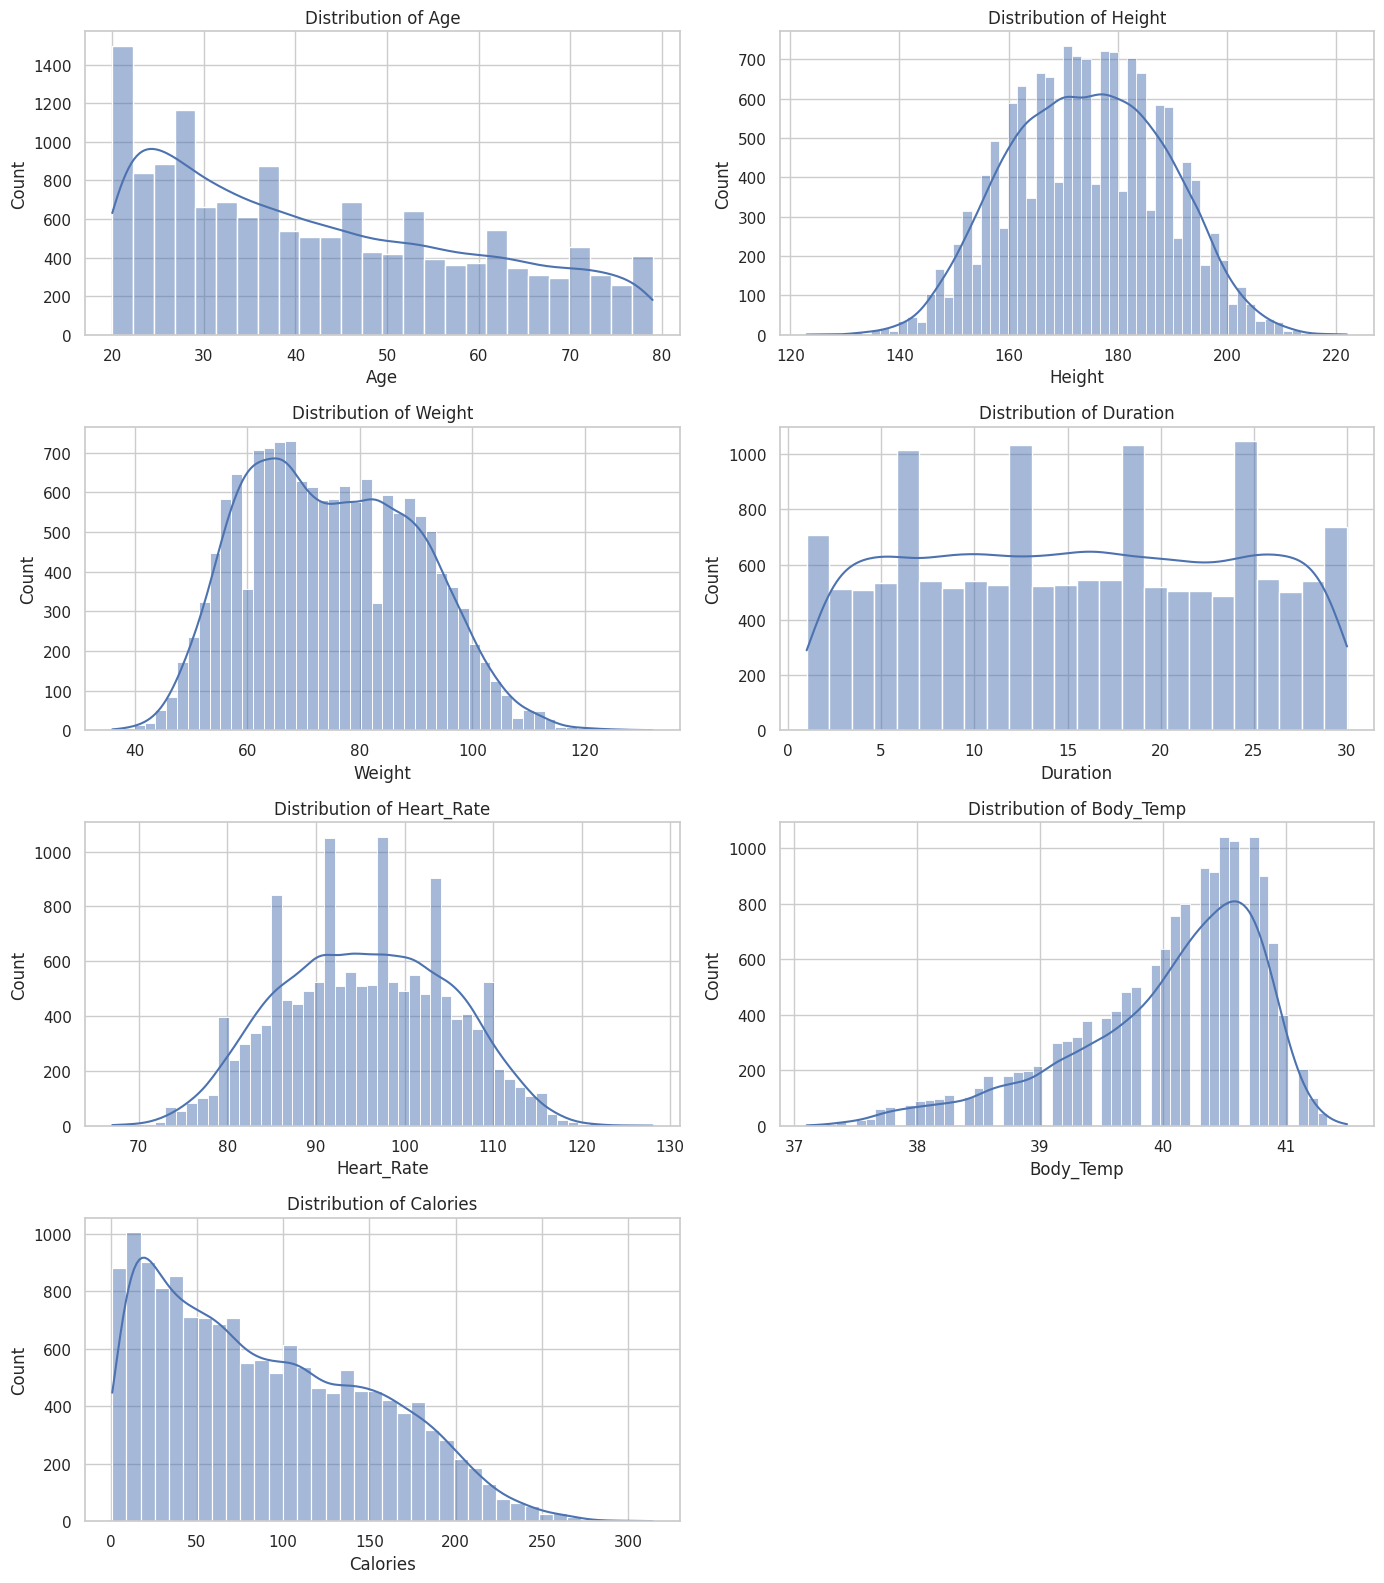

In [8]:
numerical_features = [
    "Age",
    "Height",
    "Weight",
    "Duration",
    "Heart_Rate",
    "Body_Temp",
    "Calories"
]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    sns.histplot(
        data=calories_data,
        x=feature,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution of {feature}")

# Hide the unused final subplot
axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

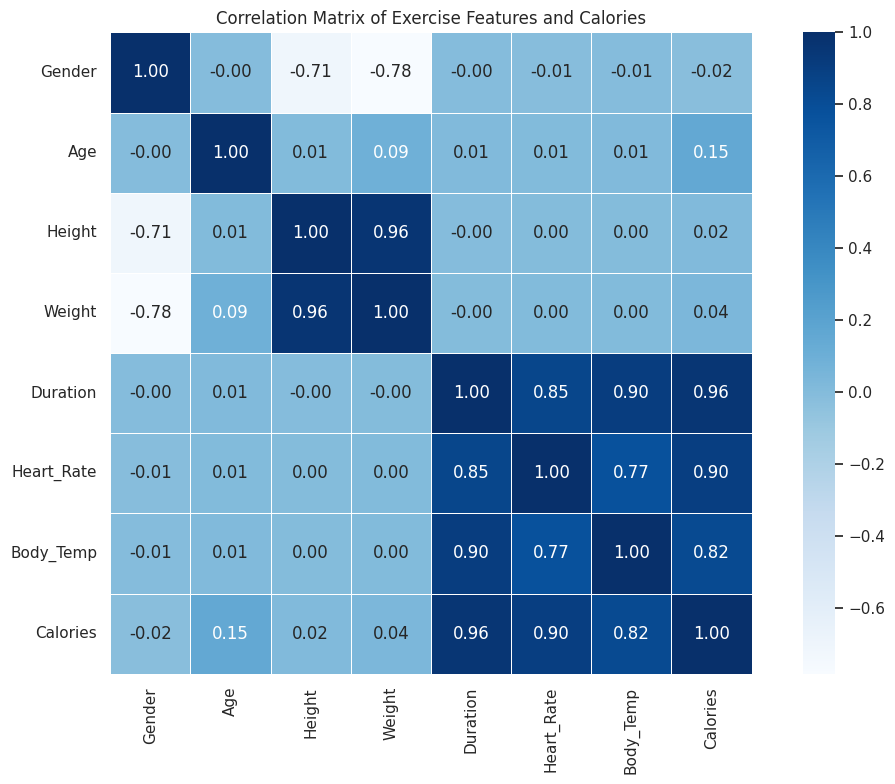

In [9]:
correlation_data = calories_data.drop(columns=["User_ID"]).copy()

correlation_data["Gender"] = correlation_data["Gender"].map({
    "male": 0,
    "female": 1
})

assert correlation_data["Gender"].notna().all(), (
    "Unexpected Gender category found. Inspect the dataset."
)

correlation_matrix = correlation_data.corr(numeric_only=True)

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    square=True,
    linewidths=0.5
)

plt.title("Correlation Matrix of Exercise Features and Calories")
plt.tight_layout()
plt.show()

## 5. Data Preprocessing and Feature Selection

Before training the model, we separate the input features from the target variable.

- **Target:** `Calories`
- **Excluded identifier:** `User_ID`
- **Categorical feature:** `Gender`
- **Numerical features:** Age, Height, Weight, Duration, Heart_Rate, and Body_Temp

The `User_ID` column is excluded because it identifies records rather than representing a meaningful exercise characteristic. Gender is encoded numerically so that it can be used by the machine learning model.

In [10]:
# Create a copy to preserve the original merged dataset
model_data = calories_data.copy()

# Encode Gender
model_data["Gender"] = model_data["Gender"].map({
    "male": 0,
    "female": 1
})

# Verify encoding
assert model_data["Gender"].notna().all(), "Unexpected Gender category found."

# Separate features and target
X = model_data.drop(columns=["User_ID", "Calories"])
y = model_data["Calories"]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("\nFeatures:", X.columns.tolist())

display(X.head())
display(y.head())

Feature matrix shape: (15000, 7)
Target vector shape: (15000,)

Features: ['Gender', 'Age', 'Height', 'Weight', 'Duration', 'Heart_Rate', 'Body_Temp']


,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
0,0,68,190.0,94.0,29.0,105.0,40.8
1,1,20,166.0,60.0,14.0,94.0,40.3
2,0,69,179.0,79.0,5.0,88.0,38.7
3,1,34,179.0,71.0,13.0,100.0,40.5
4,1,27,154.0,58.0,10.0,81.0,39.8


,Calories
0,231.0
1,66.0
2,26.0
3,71.0
4,35.0


## 6. Splitting the Dataset

We split the dataset into training and testing subsets.

- **Training set (80%):** Used to train the model.
- **Testing set (20%):** Used to evaluate performance on unseen records.

A fixed random state ensures reproducibility.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (12000, 7)
Testing features: (3000, 7)
Training targets: (12000,)
Testing targets: (3000,)


## 7. Model Training

We train two regression models:

1. **Dummy Regressor:** A baseline that predicts the mean target value.
2. **XGBoost Regressor:** A gradient-boosting model that learns nonlinear relationships between exercise features and calorie expenditure.

The baseline provides a reference point for determining whether XGBoost offers meaningful predictive improvement.

In [12]:
from sklearn.dummy import DummyRegressor

# Baseline model
baseline_model = DummyRegressor(strategy="mean")
baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

# XGBoost model
model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# Generate predictions
y_pred = model.predict(X_test)

print("Baseline and XGBoost models trained successfully.")

Baseline and XGBoost models trained successfully.


## 8. Model Evaluation

We evaluate both models using three regression metrics:

- **MAE (Mean Absolute Error):** Average absolute prediction error, measured in calories.
- **RMSE (Root Mean Squared Error):** Penalizes larger errors more strongly.
- **R² Score:** Measures how much target variability is explained by the model relative to a mean-prediction baseline.

Lower MAE and RMSE are better. Higher R² is generally better.

In [13]:
def evaluate_regression(y_true, predictions):
    return {
        "MAE": mean_absolute_error(y_true, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
        "R2 Score": r2_score(y_true, predictions)
    }

baseline_results = evaluate_regression(y_test, baseline_predictions)
xgboost_results = evaluate_regression(y_test, y_pred)

results = pd.DataFrame(
    [baseline_results, xgboost_results],
    index=["Dummy Regressor", "XGBoost Regressor"]
)

display(results.round(4))

,MAE,RMSE,R2 Score
Dummy Regressor,53.9279,63.5667,-0.0012
XGBoost Regressor,1.1964,1.6341,0.9993


## 9. Actual vs. Predicted Calories

This plot compares actual calorie values with the predictions generated by XGBoost.

Points closer to the diagonal reference line indicate more accurate predictions.

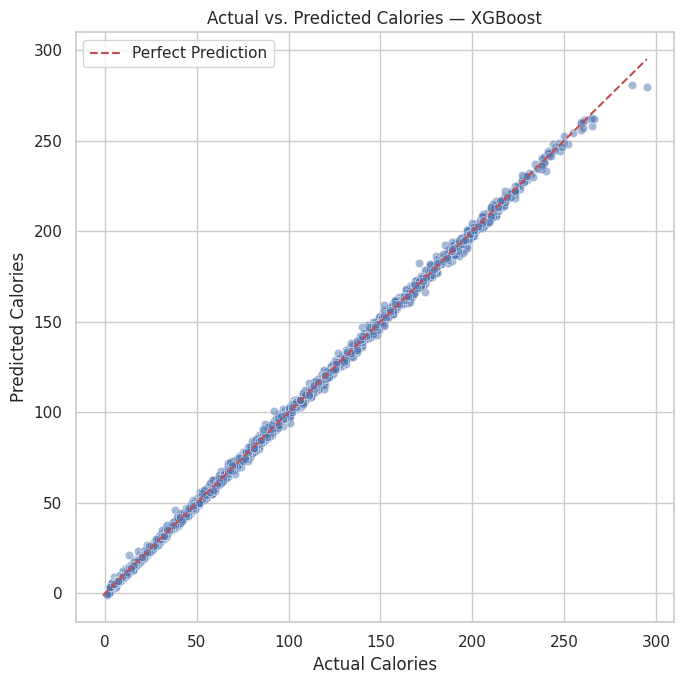

In [14]:
plt.figure(figsize=(7, 7))

sns.scatterplot(x=y_test, y=y_pred, alpha=0.5)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Calories")
plt.ylabel("Predicted Calories")
plt.title("Actual vs. Predicted Calories — XGBoost")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Feature Importance

XGBoost provides feature-importance estimates that help us understand which input features contributed most to the model's predictions.

These values describe the model's use of features; they do not prove that a feature causes higher calorie expenditure.

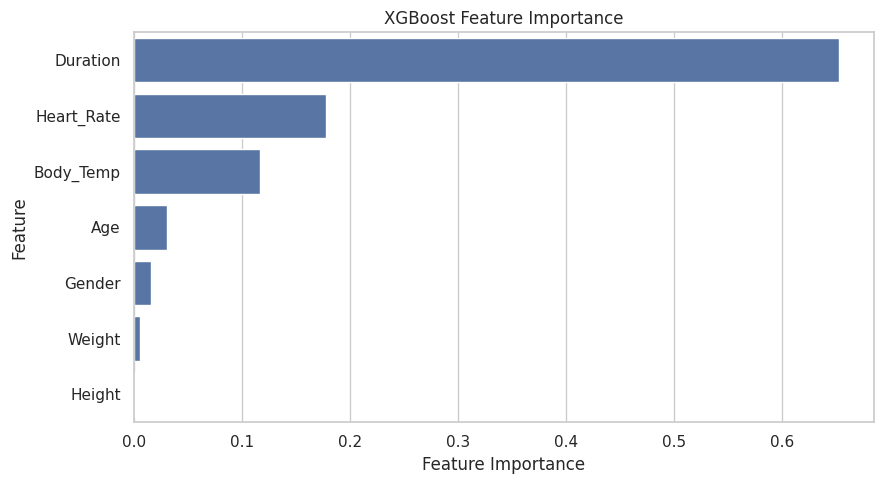

,Importance
Duration,0.652584
Heart_Rate,0.177844
Body_Temp,0.116439
Age,0.030768
Gender,0.015431
Weight,0.005487
Height,0.001446


In [15]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=feature_importance.values,
    y=feature_importance.index
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance")
plt.tight_layout()
plt.show()

display(feature_importance.to_frame("Importance"))

## 11. Generalization and Residual Analysis

A strong test score should be interpreted alongside training performance and prediction errors.

We compare training and testing metrics and examine residuals, defined as the difference between actual and predicted calorie values.

This analysis helps identify possible overfitting and systematic prediction errors.

,MAE,RMSE,R2 Score
Training Set,1.0011,1.3299,0.9995
Testing Set,1.1964,1.6341,0.9993


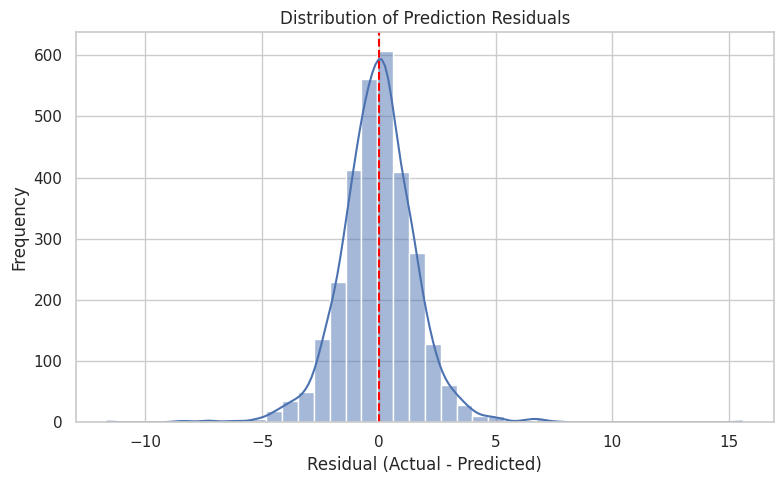

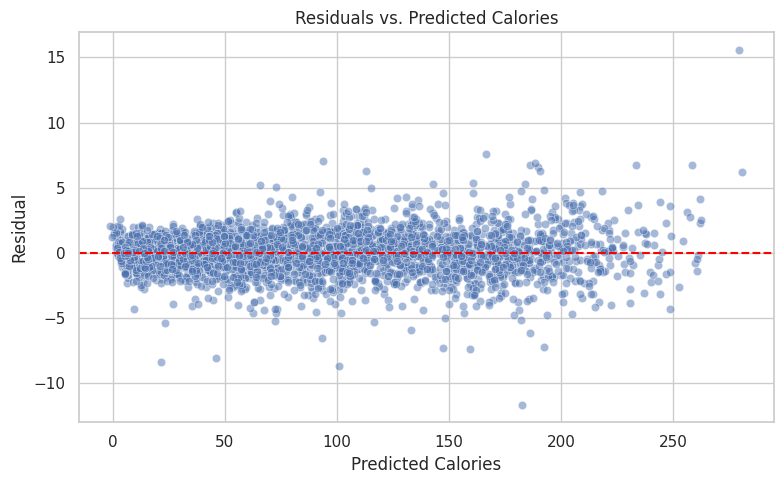

In [16]:
# Evaluate training and testing performance
train_predictions = model.predict(X_train)

train_results = evaluate_regression(y_train, train_predictions)
test_results = evaluate_regression(y_test, y_pred)

generalization_results = pd.DataFrame(
    [train_results, test_results],
    index=["Training Set", "Testing Set"]
)

display(generalization_results.round(4))

# Calculate residuals
residuals = y_test - y_pred

# Residual distribution
plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=40, kde=True)

plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Residuals")
plt.tight_layout()
plt.show()

# Residuals versus predicted values
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.5)

plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Calories")
plt.ylabel("Residual")
plt.title("Residuals vs. Predicted Calories")
plt.tight_layout()
plt.show()

## 12. Conclusion

This project developed an XGBoost regression model to predict calories burned during exercise using personal and exercise-related features.

The workflow included dataset inspection, merging records using `User_ID`, exploratory data analysis, feature encoding, train-test splitting, baseline comparison, model training, and regression evaluation.

On the held-out test set, the XGBoost model achieved an MAE of approximately 1.1964, an RMSE of approximately 1.6341, and an R² score of 0.9993. These results substantially outperformed the mean-prediction baseline on this dataset.

Duration was the most important feature according to the model's feature-importance scores, followed by Heart_Rate and Body_Temp.

However, these results describe performance on this particular dataset and split. Further validation on independent data is necessary before concluding that the model will perform similarly in real-world exercise scenarios.

### Limitations and Future Improvements

- Validate performance on an independent dataset.
- Investigate why the model achieves an exceptionally high R² score.
- Compare XGBoost with additional regression algorithms.
- Use cross-validation and hyperparameter tuning.
- Examine feature importance with complementary interpretation methods.